# SPHEREx × DESI real-space cross-correlation: ELGs, OUTLIER allowed

Re-run of the ELG z-slice (1.0 < z < 1.01, 27,803 ELGs, 5× randoms), made from `2026-09-28-claude-lrg.ipynb` with
the ELG catalogs swapped back in. Compared with `2026-09-24-claude-v2.ipynb` (the previous ELG run):

- **`ALLOWED_FLAGS` also allows OUTLIER (bit 19).** In the LRG run, OUTLIER was set on 11.8% of rows at LRG centres
  vs 2.2% at random centres, and never on catalogued (SOURCE) stars. So the pipeline clips the brightest measurements of
  galaxies missing from its point-source catalog. For ELGs this would hit the Hα peak hardest. The same rule applies to
  data and randoms, so genuine glitches cancel in the difference of means.
- The follow-up diagnostics are all included: weighted / unit-weight / per-region local randoms, the HEALPix
  local-randoms scan, the Gaia-star PSF stack (stars chosen near *these* objects), and the flag accounting, which now
  also shows how often OUTLIER is set per wavelength bin.
- Outputs: `../data/stack_2026-09-28-elg-outlier.npz`, `../data/psf_stack_2026-09-28-elg.npz`. The PSF comparison
  also overlays the previous ELG Hα excess (OUTLIER rejected) and the LRG continuum (OUTLIER allowed) if those files exist.

What to compare against v2: the central Hα line excess (was 1.01e13, S/N 16), the Hα-bin pair-count ratio at the
centre (was about 1% low), and the large-r continuum offset (was about −2e12, removed by ~0.5° local randoms).


In [1]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import hashlib
import itertools
import threading
import time
import warnings
from collections import defaultdict
from glob import glob
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from pathlib import Path

import duckdb
import healpy as hp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import pyvo
from astropy import constants as const
from astropy import units as u
from astropy.cosmology import Planck18
from astropy.io import fits
from astropy.table import Table, unique, vstack
from pyvo.dal.exceptions import DALServiceError
from scipy.cluster.vq import kmeans2
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

from talltable.constants import HP_HIGH_LEVEL
from talltable.partition import find_partitions_disc, part_to_level_index
from talltable.paths import PART_DB_PATH, PIXEL_DB_PATH, WAVES_DB_PATH
from talltable.query import indices_to_hphigh_ranges

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


## configuration

In [2]:
Z_MIN, Z_MAX = 1.0, 1.01
N_DATA = None             # data sample size; None -> every galaxy in the z-bin
RAND_PER_DATA = 5         # N_R = RAND_PER_DATA * N_D (capped by what the random files hold)

TRACER = 'ELG'
DATA_PATH  = '../data/ELG_LOPnotqso_NGC_clustering.dat.fits'
RAND_PATHS = sorted(glob('../data/ELG_LOPnotqso_NGC_*_clustering.ran.fits'))   # every random file present
assert RAND_PATHS, "no random catalogs found"

WL_REST_HALPHA = 0.656    # µm
N_WL_BINS = 9
RESOLUTION = 40           # ~ SPHEREx band-3 resolving power

R_MAX_CMPC = 0.8          # comoving transverse radius of the stack [Mpc]
R_BIN_MIN = 0.05          # first radial bin is [0, R_BIN_MIN]; log-spaced above
N_R_BINS = 8

GAIA_G_MAX = 20.0         # mask Gaia stars brighter than this
GAIA_G_BRIGHT = 9.0       # stars brighter than this are fetched all-sky (their masks are large)
GAIA_CACHE_DIR = Path('../data/gaia_cache')

ALLOWED_FLAGS = (1 << 21) | (1 << 19)   # allow SOURCE (21) and OUTLIER (19), reject every other flag.
                                        # OUTLIER clips faint galaxies missing from the SPHEREx source catalog
RANGE_LEVEL = 14          # HEALPix level of the hphigh ranges used to select row groups and rows

N_WORKERS = 16            # partitions processed concurrently (reads are latency-bound on ceph)

N_JACKKNIFE = 50          # sky regions for jackknife errors

OUT_PATH = Path('../data/stack_2026-09-28-elg-outlier.npz')   # previous ELG run (OUTLIER rejected): stack_2026-09-24-v2.npz
CHECKPOINT_PATH = OUT_PATH.with_suffix('.partial.npz')
CHECKPOINT_EVERY_S = 300


RNG = np.random.default_rng(110)

## load catalogs

In [3]:
def load_catalog(paths, n=None):
    cols = defaultdict(list)
    for path in paths:
        with fits.open(path, memmap=True) as hdul:
            x = hdul[1].data
            m = (x['Z'] > Z_MIN) & (x['Z'] < Z_MAX)
            print(f"  {Path(path).name}: {len(x)} rows, {m.sum()} after z cuts")
            cols['ra'].append(np.array(x['RA'][m], dtype=np.float64))
            cols['dec'].append(np.array(x['DEC'][m], dtype=np.float64))
            cols['z'].append(np.array(x['Z'][m], dtype=np.float64))
            if 'WEIGHT' in x.columns.names:
                cols['w'].append(np.array(x['WEIGHT'][m], dtype=np.float64))
            else:
                print(f"  WARNING: no WEIGHT column in {path}; using unit weights")
                cols['w'].append(np.ones(m.sum()))
    cat = {k: np.concatenate(v) for k, v in cols.items()}

    if n is not None:
        if n > len(cat['z']):
            print(f"  WARNING: asked for {n} objects but only {len(cat['z'])} available; using all")
        else:
            idx = RNG.choice(len(cat['z']), size=n, replace=False)
            cat = {k: v[idx] for k, v in cat.items()}
            print(f"  ..subsampled to {n}")
    return cat

print("Loading data:")
data = load_catalog([DATA_PATH], N_DATA)

print("\nLoading randoms:")
rand = load_catalog(RAND_PATHS, RAND_PER_DATA * len(data['z']))

N_D, N_R = len(data['z']), len(rand['z'])
print(f"\nN_D = {N_D}, N_R = {N_R} (ratio {N_R / N_D:.1f})")
print(f"sum of weights: data {data['w'].sum():.1f}, randoms {rand['w'].sum():.1f}")

Loading data:
  ELG_LOPnotqso_NGC_clustering.dat.fits: 1821322 rows, 27803 after z cuts

Loading randoms:
  ELG_LOPnotqso_NGC_0_clustering.ran.fits: 9719822 rows, 147732 after z cuts
  ELG_LOPnotqso_NGC_1_clustering.ran.fits: 9715719 rows, 148011 after z cuts
  ..subsampled to 139015

N_D = 27803, N_R = 139015 (ratio 5.0)
sum of weights: data 26810.0, randoms 120753.1


In [4]:
# one combined object table: data first, then randoms
objs = {k: np.concatenate([data[k], rand[k]]) for k in data}
is_rand = np.r_[np.zeros(N_D, bool), np.ones(N_R, bool)]
n_obj = len(is_rand)

obj_D_M   = Planck18.comoving_transverse_distance(objs['z']).to(u.Mpc).value
obj_theta = R_MAX_CMPC / obj_D_M                                   # stack radius [rad]
obj_vec   = hp.ang2vec(objs['ra'], objs['dec'], lonlat=True)       # (n_obj, 3) unit vectors

print(f"stack radius: {np.degrees(obj_theta).min() * 60:.3f}' - {np.degrees(obj_theta).max() * 60:.3f}'")

stack radius: 0.804' - 0.810'


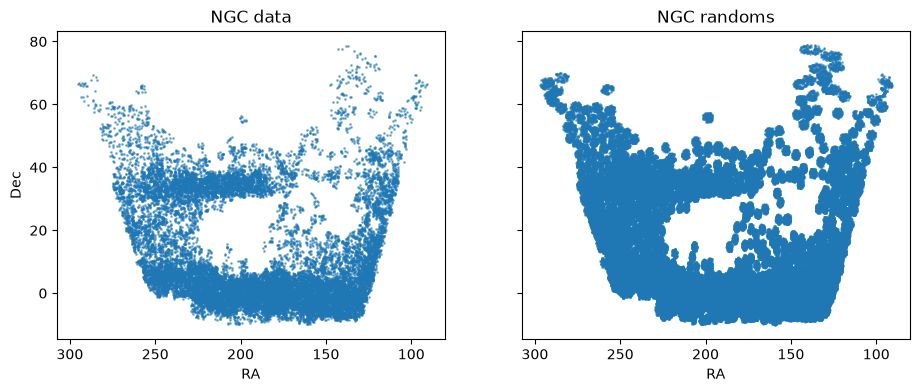

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, sel, title in [(axs[0], ~is_rand, 'data'), (axs[1], is_rand, 'randoms')]:
    ax.scatter(objs['ra'][sel], objs['dec'][sel], s=1, alpha=0.5)
    ax.set_title(f'NGC {title}')
    ax.set_xlabel('RA')
axs[0].set_ylabel('Dec')
axs[0].xaxis.set_inverted(True)
plt.show()

## choose bins

In [6]:
r_bins = np.r_[0, np.geomspace(R_BIN_MIN, R_MAX_CMPC, N_R_BINS)]

# rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every object's redshifted window
QUERY_WL_MIN = WL_REST_MIN * (1 + objs['z'].min())
QUERY_WL_MAX = WL_REST_MAX * (1 + objs['z'].max())

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1
n_bins = n_r * n_wl

r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

print("r edges [cMpc]:", np.round(r_bins, 3))
print("λ_rf edges [nm]:", np.round(wl_bins * 1e3, 1))

r edges [cMpc]: [0.    0.05  0.074 0.11  0.164 0.244 0.362 0.538 0.8  ]
λ_rf edges [nm]: [586.2 601.  616.3 631.9 647.9 664.3 681.1 698.3 716.  734.1]


## estimators and jackknife

With per-object sums $S_o$, counts $C_o$ and DESI weights $w_o$, and $W_X = \sum_{o \in X} w_o$:

- **difference of means**: $\hat J = \dfrac{\sum_D w S}{\sum_D w C} - \dfrac{\sum_R w S}{\sum_R w C}$
- **note's estimator**: $\hat J_{\rm note} = \dfrac{\sum_D w S / W_D - \sum_R w S / W_R}{\sum_R w C / W_R}$
- **pair-count ratio**: $(\sum_D w C / W_D) / (\sum_R w C / W_R)$. $\hat J_{\rm note} - \hat J = (\text{ratio} - 1) \langle I \rangle_D$.

Jackknife regions come from k-means on the randoms' unit vectors (randoms trace the footprint), and every object is
assigned to the nearest centroid. All weighted sums are accumulated per region, so each leave-one-out estimate is
just total − region.

**Hα line excess**: $\hat J$ in the bin containing Hα minus the mean over bins that contain none of the lines in
`LINES_NM` (or, if every bin has a line, all the other bins).

In [7]:
LINES_NM = {r'[OI]': 630.0, r'H$\alpha$': 656.3, r'[NII]': 658.4, r'[SII]': 671.6, r'[SII] ': 673.1}

def jackknife_regions(ra, dec, is_rand, n_regions, seed=0):
    vec = hp.ang2vec(ra, dec, lonlat=True)
    centroids, _ = kmeans2(vec[is_rand], n_regions, minit='++', rng=seed)
    return cKDTree(centroids).query(vec)[1]

def region_sums(S3, C3, w, region, sel, n_regions):
    # per-region weighted sums over the objects in `sel`: (n_regions, n_r, n_wl) for S and C, (n_regions,) for w
    Sg = np.zeros((n_regions,) + S3.shape[1:])
    Cg = np.zeros((n_regions,) + C3.shape[1:])
    Wg = np.zeros(n_regions)
    for g in range(n_regions):
        m = np.flatnonzero(sel & (region == g))
        Sg[g] = np.tensordot(w[m], S3[m], 1)
        Cg[g] = np.tensordot(w[m], C3[m], 1)
        Wg[g] = w[m].sum()
    return Sg, Cg, Wg

def estimators_from_sums(SD, CD, WD, SR, CR, WR):
    with np.errstate(divide='ignore', invalid='ignore'):
        J_diff = SD / CD - SR / CR
        J_note = (SD / WD - SR / WR) / (CR / WR)
        pc_ratio = (CD / WD) / (CR / WR)
    return np.array([J_diff, J_note, pc_ratio])

def measure(S3, C3, w, is_rand, region, n_regions):
    # returns (full, jk): full is (3, n_r, n_wl) = [J_diff, J_note, pc_ratio]; jk is (n_regions, 3, n_r, n_wl)
    D = region_sums(S3, C3, w, region, ~is_rand, n_regions)
    R = region_sums(S3, C3, w, region, is_rand, n_regions)
    tot = [x.sum(0) for x in D + R]
    full = estimators_from_sums(*tot)
    jk = np.array([
        estimators_from_sums(*[t - x[g] for t, x in zip(tot, D + R)])
        for g in range(n_regions)
    ])
    return full, jk

def jk_err(jk):
    n = len(jk)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        return np.sqrt((n - 1) / n * np.nansum((jk - np.nanmean(jk, axis=0)) ** 2, axis=0))

def line_and_continuum(wl_bins):
    lo, hi = wl_bins[:-1] * 1e3, wl_bins[1:] * 1e3
    has_line = np.array([any(l <= x < h for x in LINES_NM.values()) for l, h in zip(lo, hi)])
    j_line = np.flatnonzero((lo <= WL_REST_HALPHA * 1e3) & (WL_REST_HALPHA * 1e3 < hi))[0]
    cont = np.flatnonzero(~has_line)
    if len(cont) == 0:
        cont = np.setdiff1d(np.arange(len(lo)), [j_line])
    return j_line, cont

def line_excess(J, j_line, cont):
    # works on (..., n_r, n_wl)
    return J[..., j_line] - J[..., cont].mean(axis=-1)

def plot_J(full, jk, r_bins, wl_bins, title=''):
    J, J_err = full[0], jk_err(jk[:, 0])
    rc = 0.5 * (r_bins[:-1] + r_bins[1:])
    wc = 0.5 * (wl_bins[:-1] + wl_bins[1:])
    j_line, cont = line_and_continuum(wl_bins)

    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))

    ax = axs[0]
    cmap, norm = plt.get_cmap('viridis'), mpl.colors.Normalize(rc.min(), rc.max())
    for i in range(len(rc)):
        ax.errorbar(wc * 1e3, J[i], J_err[i], marker='o', capsize=2, color=cmap(norm(rc[i])))
    for name, x in LINES_NM.items():
        ax.axvline(x, color='0.7', lw=0.8, ls='--', zorder=0)
        ax.text(x, 1.0, name.strip(), transform=ax.get_xaxis_transform(), rotation=90, va='top', ha='right', fontsize=8)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel(r'$\lambda_{\rm rf}$ [nm]')
    ax.set_ylabel(r'$\hat J$')
    fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$r_\perp$ [cMpc]')

    ax = axs[1]
    ax.errorbar(rc, J[:, j_line], J_err[:, j_line], marker='o', capsize=2, label=rf'H$\alpha$ bin ({wc[j_line] * 1e3:.0f} nm)')
    cont_J = J[:, cont].mean(1)
    cont_err = jk_err(jk[:, 0][:, :, cont].mean(-1))
    ax.errorbar(rc, cont_J, cont_err, marker='s', capsize=2, label=f'continuum ({len(cont)} bins)')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'$\hat J$')
    ax.legend()

    ax = axs[2]
    ex = line_excess(J, j_line, cont)
    ex_err = jk_err(line_excess(jk[:, 0], j_line, cont))
    ax.errorbar(rc, ex, ex_err, marker='o', capsize=2, color='C3')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'H$\alpha$ line excess')

    fig.suptitle(title)
    plt.show()

    print(f"H-alpha line excess (bin {wc[j_line] * 1e3:.0f} nm minus continuum bins {np.round(wc[cont] * 1e3).astype(int)} nm):")
    for i in range(len(rc)):
        print(f"  r = {r_bins[i]:.3f} - {r_bins[i + 1]:.3f} cMpc: {ex[i]: .3e} ± {ex_err[i]:.3e}  (S/N {ex[i] / ex_err[i]: .1f})")

## Gaia star mask

Two tiers, both fetched once from IRSA TAP and cached under `GAIA_CACHE_DIR`:

- **bright** (`G < GAIA_G_BRIGHT`): all-sky, ~180k stars, ~35 s (cached from the first run). These have masks up to degrees, so
  they must be found far from the objects.
- **faint** (`GAIA_G_BRIGHT <= G < GAIA_G_MAX`): a single upload-join cone search around every object
  (chunked), with radius = largest stack radius + mask radius at `GAIA_G_BRIGHT`. About 10 s per 2000
  objects.

The faint-tier cache file is keyed by a hash of the object positions and query radius, so changing the
sample triggers a re-fetch. To force one, delete the cache files.

With ~170k objects the faint-tier fetch is ~35 upload queries; expect roughly 10 minutes the first time.

In [8]:
IRSA_TAP = pyvo.dal.TAPService('https://irsa.ipac.caltech.edu/TAP')

def crude_mask_radius(m):
    # arcsec
    return 8.0 + 4e3 * 10 ** (-0.25 * m)

def run_tap(query, uploads=None, max_retries=5):
    for attempt in range(max_retries):
        try:
            return IRSA_TAP.run_async(query, uploads=uploads, maxrec=50_000_000).to_table()
        except DALServiceError:
            if attempt == max_retries - 1:
                raise
            time.sleep(2 ** attempt + np.random.uniform(0, 1))

def fetch_gaia_bright():
    cache = GAIA_CACHE_DIR / f'gaia_dr3_G_lt_{GAIA_G_BRIGHT:g}.fits'
    if cache.exists():
        return Table.read(cache)
    t = run_tap(f'''
SELECT source_id, ra, dec, phot_g_mean_mag
FROM gaia_dr3_source
WHERE phot_g_mean_mag < {GAIA_G_BRIGHT}
''')
    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

def fetch_gaia_near(ra, dec, radius_deg, chunk=5000):
    key = hashlib.sha1(
        np.round(ra, 6).tobytes() + np.round(dec, 6).tobytes()
        + f'{radius_deg:.6f},{GAIA_G_BRIGHT},{GAIA_G_MAX}'.encode()
    ).hexdigest()[:12]
    cache = GAIA_CACHE_DIR / f'gaia_dr3_near_{key}.fits'
    if cache.exists():
        return Table.read(cache)

    query = f'''
SELECT g.source_id, g.ra, g.dec, g.phot_g_mean_mag
FROM gaia_dr3_source AS g, TAP_UPLOAD.objs AS o
WHERE 1 = CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', o.ra, o.dec, {radius_deg}))
AND g.phot_g_mean_mag >= {GAIA_G_BRIGHT}
AND g.phot_g_mean_mag < {GAIA_G_MAX}
'''
    tables = []
    for i in tqdm(range(0, len(ra), chunk), desc='gaia (faint)'):
        upload = Table({'ra': ra[i:i + chunk], 'dec': dec[i:i + chunk]})
        tables.append(run_tap(query, uploads={'objs': upload}))
    t = unique(vstack(tables), keys='source_id')   # neighboring cones overlap

    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

In [9]:
def make_star_set(t):
    g = np.ma.filled(np.asarray(t['phot_g_mean_mag'], dtype=np.float64), np.nan)
    ok = np.isfinite(g)
    ra, dec = np.asarray(t['ra'], np.float64)[ok], np.asarray(t['dec'], np.float64)[ok]
    vec = hp.ang2vec(ra, dec, lonlat=True).reshape(-1, 3)
    r_mask = np.radians(crude_mask_radius(g[ok]) / 3600)
    return {
        'vec': vec,
        'r_mask': r_mask,
        'r_max': r_mask.max() if len(r_mask) else 0.0,
        'tree': cKDTree(vec),
    }

t0 = time.time()
gaia_bright = fetch_gaia_bright()
faint_radius_deg = np.degrees(obj_theta.max()) + crude_mask_radius(GAIA_G_BRIGHT) / 3600
gaia_faint = fetch_gaia_near(objs['ra'], objs['dec'], faint_radius_deg)
print(f"Gaia: {len(gaia_bright)} bright + {len(gaia_faint)} faint stars ({time.time() - t0:.0f} s)")

star_sets = [make_star_set(gaia_bright), make_star_set(gaia_faint)]

Gaia: 177426 bright + 955518 faint stars (0 s)


## assign objects to partitions

Each talltable partition is a nested-HEALPix cell (levels 6-10, adaptive) and every sky pixel belongs to
exactly one partition. Build the inverse map partition → [objects whose disc touches it].

In [10]:
with open(PART_DB_PATH) as f:
    ALL_PARTS = {int(line) for line in f if line.strip()}

part_objs = defaultdict(list)
for k in tqdm(range(n_obj), desc='partitions'):
    for p in find_partitions_disc(objs['ra'][k], objs['dec'][k], np.degrees(obj_theta[k]), all_parts=ALL_PARTS):
        part_objs[int(p)].append(k)
part_objs = {p: np.array(ks) for p, ks in part_objs.items()}

n_per_part = np.array([len(ks) for ks in part_objs.values()])
n_pairs = n_per_part.sum()
print(f"{len(part_objs)} partitions for {n_obj} objects")
print(f"objects per partition: median {np.median(n_per_part):.0f}, max {n_per_part.max()}")
print(f"(object, partition) pairs: {n_pairs} ({n_pairs / n_obj:.2f} partitions per object)")

partitions:   0%|          | 0/166818 [00:00<?, ?it/s]

8495 partitions for 166818 objects
objects per partition: median 20, max 73
(object, partition) pairs: 182857 (1.10 partitions per object)


## query & stack

For each partition, `process_partition`:

1. builds `hphigh` ranges (level `RANGE_LEVEL`) covering the union of its objects' discs, clipped to the partition;
2. reads the parquet footer, keeps only the **row groups** whose `hphigh` min/max overlaps a range, and reads just
   those (with `pre_buffer=True`, so each row group's column chunks come in as a few large coalesced reads rather
   than scattered small ones);
3. filters rows in numpy: inside a range, allowed flags, `waveid` in the observed-frame window;
4. marks pixels inside any Gaia mask (KD-tree over the partition's unique sky pixels);
5. assigns pixels to each object with the same KD-tree, bins in `(r, λ_rest)` and returns per-object
   sums `S = Σ I_rest` and counts `C = Σ 1`, plus per-object counts of unique sky pixels inside the disc and
   inside Gaia masks (for the coverage diagnostics).

This replaced a single DuckDB query per partition: DuckDB only used the overall `hphigh` min/max for row-group
pruning, not the OR of ranges, so for objects spread across a partition it scanned most of the file (tens of millions
of rows) and evaluated hundreds of `BETWEEN`s per row.

The main thread adds the per-object results into `S_all`, `C_all` with shape `(n_obj, n_r * n_wl)`.

In [11]:
# waves in the observed-frame window, loaded once, sorted by waveid for lookups
_waves = duckdb.sql(f'''
SELECT waveid, wavelength
FROM read_parquet('{WAVES_DB_PATH}')
WHERE wavelength BETWEEN {QUERY_WL_MIN} AND {QUERY_WL_MAX}
ORDER BY waveid
''').fetchnumpy()
WAVE_IDS = np.asarray(_waves['waveid'])
WAVE_WL  = np.asarray(_waves['wavelength'])
print(f"{len(WAVE_IDS)} waveids in {QUERY_WL_MIN:.4f} - {QUERY_WL_MAX:.4f} µm")

C_UM_HZ = const.c.to(u.um / u.s).value   # nu [Hz] = C_UM_HZ / lambda [µm]
PIXEL_COLUMNS = ['hphigh', 'waveid', 'flux', 'zodi', 'flags']

def chord(angle):
    # KD-trees work in 3D Euclidean distance between unit vectors
    return 2 * np.sin(0.5 * np.asarray(angle))

def flatten_idx(lists):
    return np.fromiter(itertools.chain.from_iterable(lists), dtype=np.intp)

def partition_path(part):
    return PIXEL_DB_PATH / f'part={part}' / 'compacted.parquet'

def partition_span(part):
    level, index = part_to_level_index(int(part))
    shift = 2 * (HP_HIGH_LEVEL - level)
    return index << shift, ((index + 1) << shift) - 1

def disc_ranges(vecs, radii, span, level=RANGE_LEVEL):
    # sorted, merged, inclusive hphigh ranges covering the union of discs, clipped to the partition span
    lo_p, hi_p = span
    ipix = np.concatenate([
        hp.query_disc(2**level, v, r, nest=True, inclusive=True)
        for v, r in zip(vecs, radii)
    ])
    ranges = np.array(indices_to_hphigh_ranges(ipix, level), dtype=np.int64).reshape(-1, 2)
    ranges[:, 0] = np.maximum(ranges[:, 0], lo_p)
    ranges[:, 1] = np.minimum(ranges[:, 1], hi_p)
    return ranges[ranges[:, 0] <= ranges[:, 1]]

def last_range_starting_at_or_before(x, ranges):
    # ranges are sorted and non-overlapping, so this range also has the largest `hi` among those starting <= x
    return np.searchsorted(ranges[:, 0], x, side='right') - 1

def select_row_groups(pf, ranges):
    md = pf.metadata
    j = pf.schema_arrow.get_field_index('hphigh')
    lo = np.full(md.num_row_groups, np.iinfo(np.int64).min)
    hi = np.full(md.num_row_groups, np.iinfo(np.int64).max)
    for g in range(md.num_row_groups):
        st = md.row_group(g).column(j).statistics
        if st is not None and st.has_min_max:
            lo[g], hi[g] = st.min, st.max
    # row group [lo, hi] overlaps a range iff the last range starting <= hi ends >= lo
    i = last_range_starting_at_or_before(hi, ranges)
    return np.flatnonzero((i >= 0) & (ranges[np.maximum(i, 0), 1] >= lo))

def read_partition(part, ranges):
    # returns (hphigh, wavelength, flux, zodi) for good pixels inside `ranges`, or None
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges)
    if len(rgs) == 0:
        return None
    t = pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)

    h = t.column('hphigh').to_numpy()
    i = last_range_starting_at_or_before(h, ranges)
    keep = (i >= 0) & (h <= ranges[np.maximum(i, 0), 1])
    keep &= (t.column('flags').to_numpy().astype(np.int64) & ~ALLOWED_FLAGS) == 0
    idx = np.flatnonzero(keep)

    waveid = t.column('waveid').to_numpy()[idx]
    pos = np.minimum(np.searchsorted(WAVE_IDS, waveid), len(WAVE_IDS) - 1)
    in_window = WAVE_IDS[pos] == waveid
    idx, pos = idx[in_window], pos[in_window]
    return (
        h[idx],
        WAVE_WL[pos],
        t.column('flux').to_numpy()[idx],
        t.column('zodi').to_numpy()[idx],
    )

def star_mask(pix_tree, n_pix, ks):
    masked = np.zeros(n_pix, dtype=bool)
    for st in star_sets:
        if len(st['r_mask']) == 0:
            continue
        # stars that could reach any of these objects' discs
        cand = np.unique(flatten_idx(
            st['tree'].query_ball_point(obj_vec[ks], chord(obj_theta[ks] + st['r_max']))
        ))
        if cand.size == 0:
            continue
        hits = flatten_idx(pix_tree.query_ball_point(st['vec'][cand], chord(st['r_mask'][cand])))
        masked[hits] = True
    return masked

def process_partition(part, ks):
    # returns ks, S, C (per-object binned sums/counts), n_disc, n_masked (unique sky pixels in disc / in Gaia masks)
    S = np.zeros((len(ks), n_bins))
    C = np.zeros((len(ks), n_bins), dtype=np.int64)
    n_disc = np.zeros(len(ks), dtype=np.int64)
    n_masked = np.zeros(len(ks), dtype=np.int64)

    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    if len(ranges) == 0:
        return ks, S, C, n_disc, n_masked
    rows = read_partition(part, ranges)
    if rows is None or len(rows[0]) == 0:
        return ks, S, C, n_disc, n_masked
    hphigh, wl_obs, flux, zodi = rows
    I_obs = (C_UM_HZ / wl_obs) * (flux - zodi)   # nu I_nu

    # unique sky pixels; rows grouped by pixel (CSR layout: rows of pixel i are order[starts[i]:starts[i]+counts[i]])
    upix, inv = np.unique(hphigh, return_inverse=True)
    pix_vec = np.stack(hp.pix2vec(2**HP_HIGH_LEVEL, upix, nest=True), axis=1)
    pix_tree = cKDTree(pix_vec)
    order  = np.argsort(inv, kind='stable')
    counts = np.bincount(inv, minlength=len(upix))
    starts = np.cumsum(counts) - counts

    masked = star_mask(pix_tree, len(upix), ks)

    in_disc = pix_tree.query_ball_point(obj_vec[ks], chord(obj_theta[ks]))
    for j, k in enumerate(ks):
        sel = np.asarray(in_disc[j], dtype=np.intp)
        n_disc[j] = sel.size
        sel = sel[~masked[sel]]
        n_masked[j] = n_disc[j] - sel.size
        if sel.size == 0:
            continue

        sep = 2 * np.arcsin(0.5 * np.linalg.norm(pix_vec[sel] - obj_vec[k], axis=1))
        i_r_pix = np.digitize(sep * obj_D_M[k], r_bins) - 1

        lens = counts[sel]
        rows = order[np.repeat(starts[sel] - (np.cumsum(lens) - lens), lens) + np.arange(lens.sum())]
        i_r  = np.repeat(i_r_pix, lens)
        i_wl = np.digitize(wl_obs[rows] / (1 + objs['z'][k]), wl_bins) - 1

        ok = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)
        flat = i_r[ok] * n_wl + i_wl[ok]
        I_rest = (1 + objs['z'][k]) ** 4 * I_obs[rows[ok]]
        S[j] = np.bincount(flat, weights=I_rest, minlength=n_bins)
        C[j] = np.bincount(flat, minlength=n_bins)

    return ks, S, C, n_disc, n_masked

2293671 waveids in 1.1724 - 1.4756 µm


Optional: time a random sample of partitions (cold reads) before launching the full loop, and extrapolate.

In [12]:
# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))

def profile_partition(part):
    ks = part_objs[part]
    t0 = time.perf_counter()
    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges) if len(ranges) else np.array([], int)
    t_meta = time.perf_counter() - t0

    t0 = time.perf_counter()
    if len(rgs):
        pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)
    t_read = time.perf_counter() - t0

    t0 = time.perf_counter()
    process_partition(part, ks)   # whole thing again, now with a warm cache
    t_warm = time.perf_counter() - t0

    md = pf.metadata
    size_gb = partition_path(part).stat().st_size / 1e9
    print(f"part {part}: {len(ks):2d} objs, {len(ranges):3d} ranges | "
          f"{len(rgs):3d} / {md.num_row_groups} row groups ({md.num_rows / md.num_row_groups / 1e6:.2f}M rows each; "
          f"file {size_gb:.2f} GB) | meta {t_meta:.2f}s, read (cold) {t_read:.2f}s, all (warm) {t_warm:.2f}s")
    return t_meta + t_read + t_warm

sample = np.random.default_rng(0).choice(len(parts), size=min(8, len(parts)), replace=False)
t_cold = np.mean([profile_partition(parts[k]) for k in sample])
print(f"\n~{t_cold:.2f} s per partition -> ~{t_cold * len(parts) / N_WORKERS / 60:.0f} min "
      f"for {len(parts)} partitions with {N_WORKERS} workers (if reads scale that far)")

part 1057588:  5 objs,  69 ranges |   9 / 97 row groups (1.04M rows each; file 1.76 GB) | meta 0.01s, read (cold) 2.31s, all (warm) 0.47s
part 1075617: 43 objs, 578 ranges |  43 / 72 row groups (1.05M rows each; file 1.30 GB) | meta 0.01s, read (cold) 9.60s, all (warm) 2.76s
part 1074046: 51 objs, 655 ranges |  63 / 94 row groups (1.05M rows each; file 1.69 GB) | meta 0.01s, read (cold) 12.86s, all (warm) 3.92s
part 1076185: 19 objs, 255 ranges |  25 / 77 row groups (1.04M rows each; file 1.37 GB) | meta 0.01s, read (cold) 6.36s, all (warm) 1.39s
part 1056788: 29 objs, 350 ranges |  40 / 71 row groups (1.04M rows each; file 1.28 GB) | meta 0.02s, read (cold) 6.26s, all (warm) 2.24s
part 1056777: 31 objs, 392 ranges |  33 / 70 row groups (1.04M rows each; file 1.25 GB) | meta 0.02s, read (cold) 6.47s, all (warm) 2.00s
part 1080111: 47 objs, 560 ranges |  54 / 73 row groups (1.04M rows each; file 1.31 GB) | meta 0.03s, read (cold) 7.98s, all (warm) 3.21s
part 1052928: 14 objs, 166 ranges

Main loop. Progress is checkpointed to `CHECKPOINT_PATH` every `CHECKPOINT_EVERY_S` seconds and on interrupt; re-running
this cell with the same sample and bins resumes from it. The checkpoint is deleted once the final `OUT_PATH` is written.

In [13]:
S_all = np.zeros((n_obj, n_bins))
C_all = np.zeros((n_obj, n_bins), dtype=np.int64)
npix_disc = np.zeros(n_obj, dtype=np.int64)
npix_masked = np.zeros(n_obj, dtype=np.int64)
done_parts = set()

sample_key = hashlib.sha1(
    objs['ra'].tobytes() + objs['dec'].tobytes() + objs['z'].tobytes() + r_bins.tobytes() + wl_bins.tobytes()
).hexdigest()

if CHECKPOINT_PATH.exists():
    ck = np.load(CHECKPOINT_PATH)
    if str(ck['key']) == sample_key:
        S_all, C_all = ck['S'], ck['C']
        npix_disc, npix_masked = ck['npix_disc'], ck['npix_masked']
        done_parts = set(ck['done_parts'].tolist())
        print(f"resuming from checkpoint: {len(done_parts)} partitions already done")
    else:
        print("checkpoint is for a different sample or binning; starting over")

def save_checkpoint():
    tmp = CHECKPOINT_PATH.with_name(CHECKPOINT_PATH.stem + '.tmp.npz')
    np.savez(tmp, key=sample_key, S=S_all, C=C_all, npix_disc=npix_disc, npix_masked=npix_masked,
             done_parts=np.array(sorted(done_parts), dtype=np.int64))
    tmp.replace(CHECKPOINT_PATH)

# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))
todo = [p for p in parts if p not in done_parts]

CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
t0 = last_ckpt = time.time()
# with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = {ex.submit(process_partition, p, part_objs[p]): p for p in todo}
    try:
        for fut in tqdm(as_completed(futures), total=len(futures), desc='partitions'):
            ks, S, C, nd, nm = fut.result()
            S_all[ks] += S
            C_all[ks] += C
            npix_disc[ks] += nd
            npix_masked[ks] += nm
            done_parts.add(futures[fut])
            if time.time() - last_ckpt > CHECKPOINT_EVERY_S:
                save_checkpoint()
                last_ckpt = time.time()
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True)
        save_checkpoint()
        print(f"interrupted; checkpoint saved with {len(done_parts)} / {len(parts)} partitions")
        raise
print(f"done in {time.time() - t0:.0f} s; {(C_all.sum(1) == 0).sum()} objects with no pixels")

np.savez_compressed(
    OUT_PATH, S=S_all, C=C_all, npix_disc=npix_disc, npix_masked=npix_masked,
    is_rand=is_rand, r_bins=r_bins, wl_bins=wl_bins,
    **{f'obj_{k}': v for k, v in objs.items()},
)
CHECKPOINT_PATH.unlink(missing_ok=True)

partitions:   0%|          | 0/8495 [00:00<?, ?it/s]

done in 4370 s; 28 objects with no pixels


In [14]:
# to reload a finished run instead of recomputing (after running the config, estimator and bins cells):
# f = np.load(OUT_PATH)
# S_all, C_all, is_rand, r_bins, wl_bins = f['S'], f['C'], f['is_rand'], f['r_bins'], f['wl_bins']
# npix_disc, npix_masked = f['npix_disc'], f['npix_masked']
# objs = {k[4:]: f[k] for k in f.files if k.startswith('obj_')}
# n_obj, n_r, n_wl = len(is_rand), len(r_bins) - 1, len(wl_bins) - 1
# r_c, wl_c = 0.5 * (r_bins[:-1] + r_bins[1:]), 0.5 * (wl_bins[:-1] + wl_bins[1:])

## results

jackknife: 50 regions, 62 - 1764 galaxies each


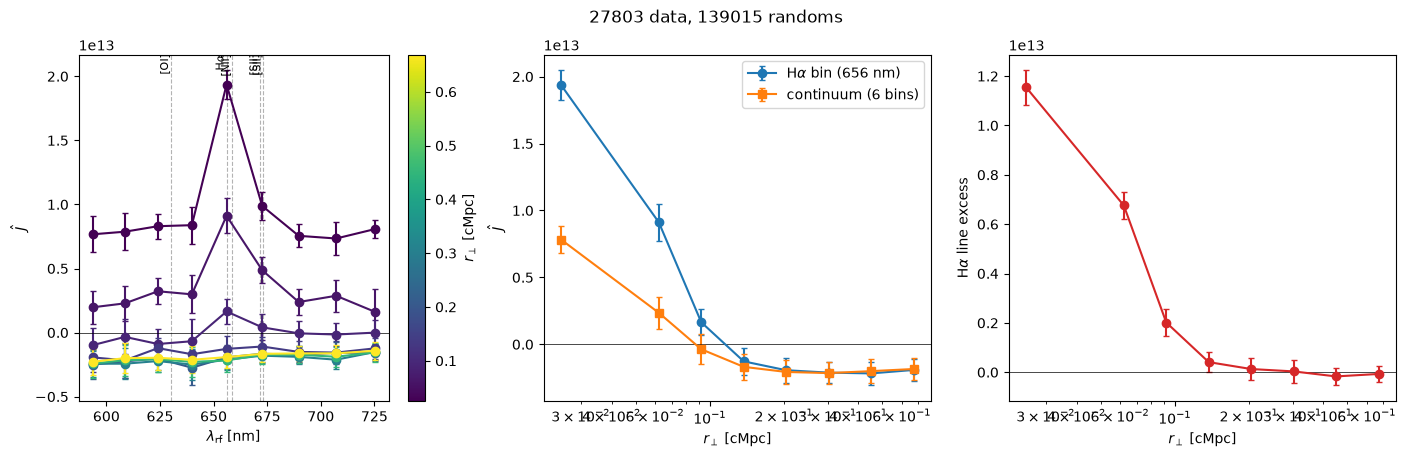

H-alpha line excess (bin 656 nm minus continuum bins [594 609 640 690 707 725] nm):
  r = 0.000 - 0.050 cMpc:  1.154e+13 ± 6.963e+11  (S/N  16.6)
  r = 0.050 - 0.074 cMpc:  6.758e+12 ± 5.298e+11  (S/N  12.8)
  r = 0.074 - 0.110 cMpc:  2.015e+12 ± 5.399e+11  (S/N  3.7)
  r = 0.110 - 0.164 cMpc:  4.097e+11 ± 4.182e+11  (S/N  1.0)
  r = 0.164 - 0.244 cMpc:  1.296e+11 ± 4.277e+11  (S/N  0.3)
  r = 0.244 - 0.362 cMpc:  3.331e+10 ± 4.570e+11  (S/N  0.1)
  r = 0.362 - 0.538 cMpc: -1.697e+11 ± 3.600e+11  (S/N -0.5)
  r = 0.538 - 0.800 cMpc: -6.988e+10 ± 3.218e+11  (S/N -0.2)


In [15]:
S3 = S_all.reshape(-1, n_r, n_wl)
C3 = C_all.reshape(-1, n_r, n_wl)
region = jackknife_regions(objs['ra'], objs['dec'], is_rand, N_JACKKNIFE)
full, jk = measure(S3, C3, objs['w'], is_rand, region, N_JACKKNIFE)
J_diff, J_note, pc_ratio = full
J_diff_err, J_note_err, pc_ratio_err = jk_err(jk)

n_per_region = np.bincount(region[~is_rand], minlength=N_JACKKNIFE)
print(f"jackknife: {N_JACKKNIFE} regions, {n_per_region.min()} - {n_per_region.max()} galaxies each")

plot_J(full, jk, r_bins, wl_bins, title=f'{(~is_rand).sum()} data, {is_rand.sum()} randoms')

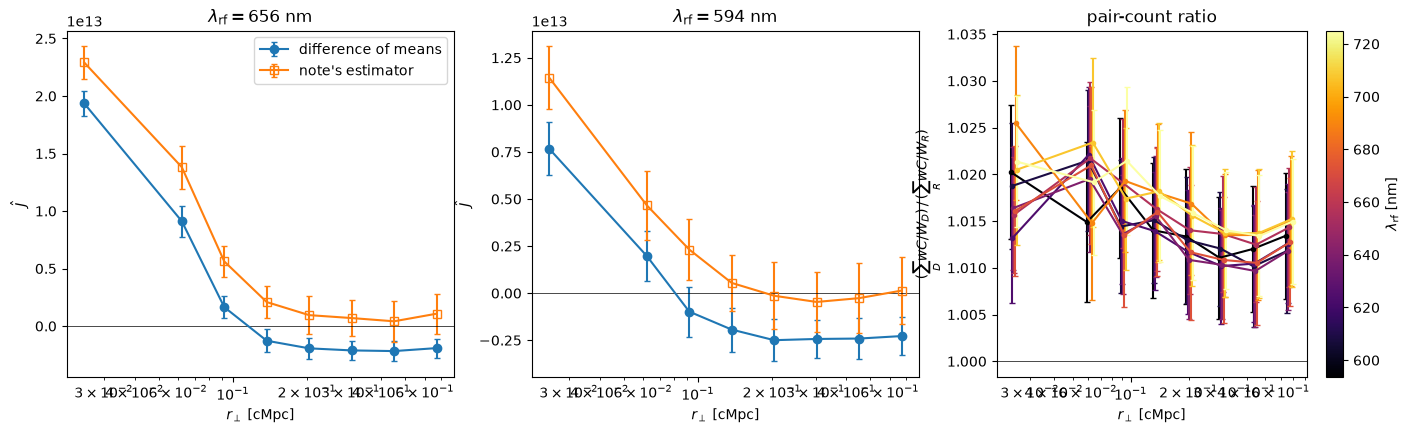

In [16]:
# the two estimators, and the pair-count ratio that separates them
j_line, cont = line_and_continuum(wl_bins)
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, j in zip(axs[:2], [j_line, cont[0]]):
    ax.errorbar(r_c, J_diff[:, j], J_diff_err[:, j], marker='o', capsize=2, label='difference of means')
    ax.errorbar(r_c, J_note[:, j], J_note_err[:, j], marker='s', mfc='none', capsize=2, label="note's estimator")
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'$\hat J$')
    ax.set_title(rf'$\lambda_{{\rm rf}} = {wl_c[j] * 1e3:.0f}$ nm')
axs[0].legend()

ax = axs[2]
cmap, norm = plt.get_cmap('inferno'), mpl.colors.Normalize(wl_c.min() * 1e3, wl_c.max() * 1e3)
for j in range(n_wl):
    ax.errorbar(r_c * (1 + 0.01 * (j - n_wl / 2)), pc_ratio[:, j], pc_ratio_err[:, j], marker='o', ms=3,
                capsize=2, color=cmap(norm(wl_c[j] * 1e3)))
ax.axhline(1, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'$(\sum_D wC / W_D) \, / \, (\sum_R wC / W_R)$')
ax.set_title('pair-count ratio')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$\lambda_{\rm rf}$ [nm]')
plt.show()

### coverage diagnostics

Is the data-vs-random difference in measurements per object (the pair-count ratio ≠ 1) real, and where does it come from?

- weighted vs **unweighted**: if only the weighted ratio is off, it's the DESI weights correlating with SPHEREx coverage;
- **unique sky pixels in the disc** (before masking) vs **measurements**: separates sky coverage from the number of exposures
  and wavelengths per pixel;
- **Gaia-masked fraction**: data and randoms should be masked equally.

Errors are jackknife over the same regions.

data / randoms                             weighted         unweighted
measurements / object              1.0131 ± 0.0062     1.0012 ± 0.0178
sky pixels in disc / object        1.0127 ± 0.0061     0.9980 ± 0.0178
measurements / unmasked pixel      1.0000 ± 0.0002     1.0001 ± 0.0002
Gaia-masked fraction               0.9989 ± 0.0114     0.9553 ± 0.0265


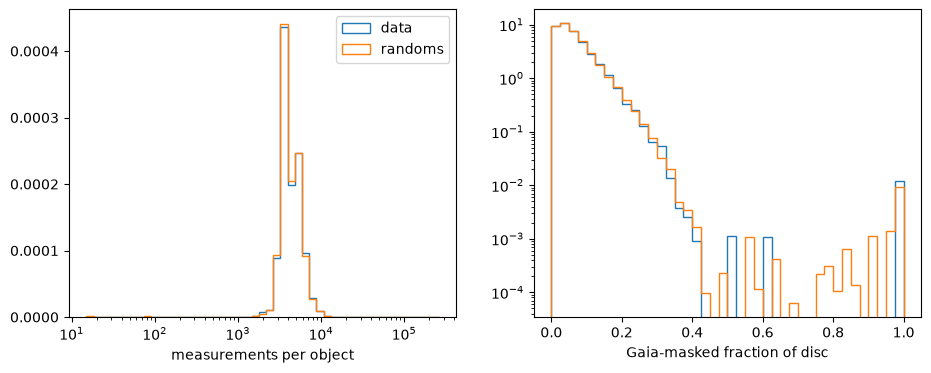

In [17]:
def ratio_jk(x, w):
    # (sum_D w x / W_D) / (sum_R w x / W_R), with jackknife error over `region`
    def ratio(keep):
        d, r = keep & ~is_rand, keep & is_rand
        return (np.sum(w[d] * x[d]) / w[d].sum()) / (np.sum(w[r] * x[r]) / w[r].sum())
    full = ratio(np.ones(n_obj, bool))
    jk = np.array([ratio(region != g) for g in range(N_JACKKNIFE)])
    return full, jk_err(jk)

n_meas = C_all.sum(1).astype(float)
masked_frac = np.where(npix_disc > 0, npix_masked / np.maximum(npix_disc, 1), np.nan)
ok = np.isfinite(masked_frac)
unit = np.ones(n_obj)

rows = [
    ('measurements / object',      n_meas),
    ('sky pixels in disc / object', npix_disc.astype(float)),
    ('measurements / unmasked pixel', np.where(npix_disc > npix_masked, n_meas / np.maximum(npix_disc - npix_masked, 1), 0.0)),
    ('Gaia-masked fraction',        np.where(ok, masked_frac, 0.0)),
]
print(f"{'data / randoms':32s} {'weighted':>18s} {'unweighted':>18s}")
for name, x in rows:
    (rw, ew), (ru, eu) = ratio_jk(x, objs['w']), ratio_jk(x, unit)
    print(f"{name:32s} {rw:8.4f} ± {ew:.4f}   {ru:8.4f} ± {eu:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
bins = np.geomspace(max(n_meas[n_meas > 0].min(), 1), n_meas.max(), 50)
for sel, label in [(~is_rand, 'data'), (is_rand, 'randoms')]:
    axs[0].hist(n_meas[sel], bins=bins, weights=objs['w'][sel], density=True, histtype='step', label=label)
    axs[1].hist(masked_frac[sel & ok], bins=np.linspace(0, 1, 41), weights=objs['w'][sel & ok], density=True,
                histtype='step', label=label)
axs[0].set_xscale('log')
axs[0].set_xlabel('measurements per object')
axs[1].set_xlabel('Gaia-masked fraction of disc')
axs[1].set_yscale('log')
axs[0].legend()
plt.show()

### large-r offset: weights vs per-region local randoms

Continuum $\hat J$ with DESI weights, unit weights, and with randoms matched per jackknife region.

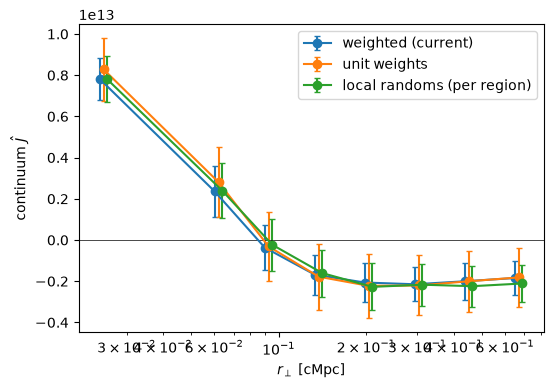

       r [cMpc]             weighted         unit weights        local randoms
0.000 - 0.050  7.81e+12 ± 1.0e+12  8.28e+12 ± 1.5e+12  7.80e+12 ± 1.1e+12
0.050 - 0.074  2.36e+12 ± 1.2e+12  2.80e+12 ± 1.7e+12  2.39e+12 ± 1.3e+12
0.074 - 0.110 -3.68e+11 ± 1.1e+12 -3.14e+11 ± 1.7e+12 -2.35e+11 ± 1.2e+12
0.110 - 0.164 -1.68e+12 ± 9.8e+11 -1.78e+12 ± 1.6e+12 -1.61e+12 ± 1.1e+12
0.164 - 0.244 -2.06e+12 ± 9.3e+11 -2.22e+12 ± 1.6e+12 -2.27e+12 ± 1.1e+12
0.244 - 0.362 -2.15e+12 ± 8.3e+11 -2.21e+12 ± 1.5e+12 -2.17e+12 ± 1.0e+12
0.362 - 0.538 -2.00e+12 ± 8.9e+11 -2.00e+12 ± 1.5e+12 -2.24e+12 ± 9.9e+11
0.538 - 0.800 -1.84e+12 ± 8.1e+11 -1.82e+12 ± 1.4e+12 -2.11e+12 ± 8.8e+11

randoms: d<I>/d ln(n_meas) = -3.85e+13; x 0.013 -> predicted offset -5.01e+11


In [18]:
def cont_mean(J):                      # (..., n_r, n_wl) -> (..., n_r), mean over the continuum bins
    return J[..., cont].mean(-1)

# weighted (what the notebook uses now)
J_w, err_w = cont_mean(full[0]), jk_err(cont_mean(jk[:, 0]))

# 1. unit weights
full_u, jk_u = measure(S3, C3, np.ones(n_obj), is_rand, region, N_JACKKNIFE)
J_u, err_u = cont_mean(full_u[0]), jk_err(cont_mean(jk_u[:, 0]))

# 2. local randoms: difference of means within each region, then a data-weighted average over regions
Sd, Cd, Wd = region_sums(S3, C3, objs['w'], region, ~is_rand, N_JACKKNIFE)
Sr, Cr, Wr = region_sums(S3, C3, objs['w'], region,  is_rand, N_JACKKNIFE)
with np.errstate(divide='ignore', invalid='ignore'):
    J_reg = cont_mean(Sd / Cd - Sr / Cr)                          # (n_regions, n_r)
good = np.isfinite(J_reg).all(1)
def loc_avg(keep):
    k = keep & good
    return (Wd[k, None] * J_reg[k]).sum(0) / Wd[k].sum()
J_l = loc_avg(np.ones(N_JACKKNIFE, bool))
err_l = jk_err(np.array([loc_avg(np.arange(N_JACKKNIFE) != g) for g in range(N_JACKKNIFE)]))

fig, ax = plt.subplots(figsize=(6, 4))
for k, (J, e, lab) in enumerate([(J_w, err_w, 'weighted (current)'), (J_u, err_u, 'unit weights'),
                                 (J_l, err_l, 'local randoms (per region)')]):
    ax.errorbar(r_c * (1 + 0.03 * (k - 1)), J, e, marker='o', capsize=2, label=lab)
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'continuum $\hat J$')
ax.legend()
plt.show()

print(f"{'r [cMpc]':>15s} {'weighted':>20s} {'unit weights':>20s} {'local randoms':>20s}")
for i in range(n_r):
    print(f"{r_bins[i]:.3f} - {r_bins[i + 1]:.3f} "
          + " ".join(f"{J[i]: .2e} ± {e[i]:.1e}" for J, e in [(J_w, err_w), (J_u, err_u), (J_l, err_l)]))

# 3. does the randoms' mean sky change with coverage?
r = is_rand & (n_meas > 0)
slope, _ = np.polyfit(np.log(n_meas[r]), S_all[r].sum(1) / n_meas[r], 1)
print(f"\nrandoms: d<I>/d ln(n_meas) = {slope:.2e}; x 0.013 -> predicted offset {slope * 0.013:.2e}")

### local-randoms scale scan

Difference of means within HEALPix patches of decreasing size. In the previous ELG run (OUTLIER rejected) the large-r offset was flat down to 1.8° and mostly gone at 0.46°.

nside   pixel data kept    mean continuum J, r > 0.16 cMpc
    8   7.33°    100.0%   -2.05e+12 ± 9.5e+11  (S/N -2.2)
   16   3.66°     99.9%   -1.96e+12 ± 9.4e+11  (S/N -2.1)
   32   1.83°     99.5%   -2.18e+12 ± 1.1e+12  (S/N -1.9)
   64   0.92°     96.2%   -1.46e+12 ± 5.9e+11  (S/N -2.5)
  128   0.46°     83.6%   -6.19e+11 ± 3.8e+11  (S/N -1.6)


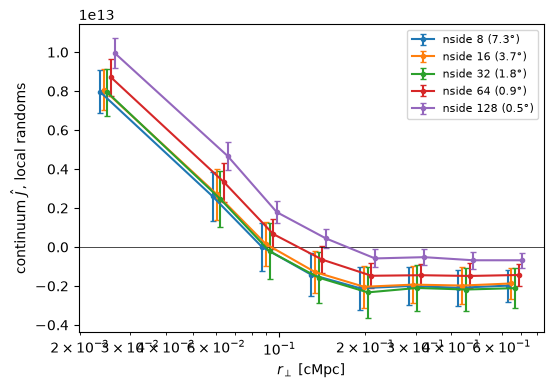

In [19]:
outer = r_c > 0.16   # r bins where the offset is flat

def group_sums(sel, g, n):
    # weighted sums of S, C, w over the objects in `sel`, grouped by g: (n, n_r, n_wl), (n, n_r, n_wl), (n,)
    w = objs['w'] * sel
    S = np.stack([np.bincount(g, weights=w * S_all[:, b], minlength=n) for b in range(n_bins)], 1)
    C = np.stack([np.bincount(g, weights=w * C_all[:, b], minlength=n) for b in range(n_bins)], 1)
    return S.reshape(n, n_r, n_wl), C.reshape(n, n_r, n_wl), np.bincount(g, weights=w, minlength=n)

def local_randoms(nside):
    pix = hp.ang2pix(nside, objs['ra'], objs['dec'], lonlat=True)
    _, first, g = np.unique(pix, return_index=True, return_inverse=True)
    n = g.max() + 1
    Sd, Cd, Wd = group_sums(~is_rand, g, n)
    Sr, Cr, _  = group_sums(is_rand, g, n)
    with np.errstate(divide='ignore', invalid='ignore'):
        Jg = cont_mean(Sd / Cd - Sr / Cr)                    # (n_pix, n_r)
    ok = np.isfinite(Jg).all(1)                              # pixel has data and randoms in every r bin
    reg = region[first]                                      # jackknife region of each pixel
    def avg(keep):
        k = keep & ok
        return (Wd[k, None] * Jg[k]).sum(0) / Wd[k].sum()
    J = avg(np.ones(n, bool))
    jk = np.array([avg(reg != r) for r in range(N_JACKKNIFE)])
    return J, jk, Wd[ok].sum() / Wd.sum()

fig, ax = plt.subplots(figsize=(6, 4))
print(f"{'nside':>5s} {'pixel':>7s} {'data kept':>9s}   {'mean continuum J, r > 0.16 cMpc':>32s}")
for k, nside in enumerate([8, 16, 32, 64, 128]):
    J_s, jk_s, frac = local_randoms(nside)
    m, m_err = J_s[outer].mean(), jk_err(jk_s[:, outer].mean(1))
    print(f"{nside:5d} {hp.nside2resol(nside, arcmin=True) / 60:6.2f}° {frac:9.1%}   {m: .2e} ± {m_err:.1e}  (S/N {m / m_err: .1f})")
    ax.errorbar(r_c * (1 + 0.03 * (k - 2)), J_s, jk_err(jk_s), marker='o', ms=3, capsize=2,
                label=f'nside {nside} ({hp.nside2resol(nside, arcmin=True) / 60:.1f}°)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'continuum $\hat J$, local randoms')
ax.legend(fontsize=8)
plt.show()

## empirical PSF from Gaia stars

Is the galaxies' emission beyond ~0.1 cMpc real extended light, or the wings of the SPHEREx PSF? Stack isolated Gaia stars
through the same pipeline (same flag cut, same talltable reads) in the **same angular bins**, i.e. the `r_bins` edges
converted to angle at the galaxies' median redshift, and in the matching **observed-frame** wavelength window, then compare
radial profiles normalized to the innermost bin.

Star selection:

- `PSF_G_MIN <= G < PSF_G_MAX` from the faint-tier Gaia catalog already fetched around the objects, and within
  `PSF_NEAR_OBJ` of some object. That keeps each star's neighbourhood inside the fetched cones and puts the stars on the
  same sky as the objects.
- **neighbours masked, target kept**: every other Gaia star's crude mask is applied as usual, but never the target's own.
  Stars with a neighbour brighter than `G_target + PSF_NBR_DMAG` whose mask reaches the stack disc are dropped, since
  its PSF wings would leak past its mask. (Requiring no neighbour at all kept only ~7% of the stars.)
- split into `PSF_G_EDGES` magnitude bins. If bright stars lose pixels to flags or nonlinearity (as the LRG centres
  did before OUTLIER was allowed), the normalized profiles will differ between bins.

Background: the mean sky from this notebook's **random** stack, converted back to observed units (divide out
`(1+z)^4`), in the same bins. As a check, a second version subtracts the star stack's own outermost bin instead. If
the two agree, the background isn't driving the profile.

About 10 min for ~1–2k stars. Needs the cells above, including the local-randoms cell (for `J_l`).

In [20]:
PSF_G_MIN, PSF_G_MAX = 12.0, 16.5
PSF_G_EDGES = [12.0, 13.5, 15.0, 16.5]
PSF_NEAR_OBJ = np.radians(0.3 / 60)          # star within 0.3' of some object
PSF_NBR_DMAG = 2.5                           # drop stars with a neighbour brighter than G_target + this near the disc
PSF_OUT_PATH = Path('../data/psf_stack_2026-09-28-elg.npz')

Z_REF = np.median(objs['z'][~is_rand])
D_M_REF = Planck18.comoving_transverse_distance(Z_REF).to(u.Mpc).value
psf_theta = R_MAX_CMPC / D_M_REF              # stack radius [rad], same as the objects'
wl_bins_obs = wl_bins * (1 + Z_REF)           # observed-frame bins matching the rest-frame bins at Z_REF
print(f"Z_REF = {Z_REF:.4f}: r bins = {np.round(np.degrees(r_bins / D_M_REF) * 3600, 1)} arcsec")

# faint-tier stars, aligned with star_sets[1] (make_star_set drops rows without G)
_g = np.ma.filled(np.asarray(gaia_faint['phot_g_mean_mag'], dtype=np.float64), np.nan)
_ok = np.isfinite(_g)
g_faint = _g[_ok]
fs, bs = star_sets[1], star_sets[0]

cand = np.flatnonzero((g_faint >= PSF_G_MIN) & (g_faint < PSF_G_MAX))
d_obj, _ = cKDTree(obj_vec).query(fs['vec'][cand], distance_upper_bound=chord(PSF_NEAR_OBJ))
cand = cand[np.isfinite(d_obj)]
n_near = len(cand)
print("  per magnitude bin:", np.histogram(g_faint[cand], PSF_G_EDGES)[0])

# drop stars with a bright neighbour (brighter than G_target + PSF_NBR_DMAG) whose mask reaches the stack disc;
# fainter neighbours are just masked in the stack
g_bright = np.ma.filled(np.asarray(gaia_bright['phot_g_mean_mag'], dtype=np.float64), np.nan)
g_bright = g_bright[np.isfinite(g_bright)]
keep = np.ones(len(cand), bool)
for st, g_st, same_set in [(fs, g_faint, True), (bs, g_bright, False)]:
    nbrs = st['tree'].query_ball_point(fs['vec'][cand], chord(psf_theta + st['r_max']))
    for i, (c, nb) in enumerate(zip(cand, nbrs)):
        nb = np.asarray(nb, dtype=np.intp)
        if same_set:
            nb = nb[nb != c]
        nb = nb[g_st[nb] < g_faint[c] + PSF_NBR_DMAG]
        if nb.size == 0:
            continue
        sep = 2 * np.arcsin(0.5 * np.linalg.norm(st['vec'][nb] - fs['vec'][c], axis=1))
        if np.any(sep < psf_theta + st['r_mask'][nb]):
            keep[i] = False
cand = cand[keep]

psf_fs_idx = cand                              # index of each target in star_sets[1], so its own mask can be skipped
psf_vec = fs['vec'][cand]
psf_g = g_faint[cand]
psf_ra, psf_dec = hp.vec2ang(psf_vec, lonlat=True)
n_psf = len(cand)
print(f"{n_near} stars with {PSF_G_MIN} <= G < {PSF_G_MAX} near objects; {n_psf} without a bright neighbour")
print("per magnitude bin:", np.histogram(psf_g, PSF_G_EDGES)[0])

psf_part_objs = defaultdict(list)
for k in tqdm(range(n_psf), desc='partitions'):
    for p in find_partitions_disc(psf_ra[k], psf_dec[k], np.degrees(psf_theta), all_parts=ALL_PARTS):
        psf_part_objs[int(p)].append(k)
psf_part_objs = {p: np.array(ks) for p, ks in psf_part_objs.items()}
print(f"{len(psf_part_objs)} partitions")

Z_REF = 1.0050: r bins = [ 0.   3.   4.5  6.7  9.9 14.8 21.9 32.6 48.4] arcsec
  per magnitude bin: [   0 1040 4841]
5881 stars with 12.0 <= G < 16.5 near objects; 1359 without a bright neighbour
per magnitude bin: [  0 428 931]


partitions:   0%|          | 0/1359 [00:00<?, ?it/s]

1297 partitions


In [21]:
def psf_star_masks(pix_tree, n_pix, ks):
    # (common, n_target, own): `common` masks pixels near non-target Gaia stars; `n_target` counts how many of this
    # partition's target stars cover each pixel, and own[j] lists the pixels covered by target j itself. Star j's
    # mask is common | (n_target - [pixel in own[j]] > 0), i.e. every star except itself.
    targets = set(psf_fs_idx[ks].tolist())
    common = np.zeros(n_pix, dtype=bool)
    for st, same_set in [(star_sets[0], False), (star_sets[1], True)]:
        cand = np.unique(flatten_idx(st['tree'].query_ball_point(psf_vec[ks], chord(psf_theta + st['r_max']))))
        if same_set:
            cand = np.array([c for c in cand if c not in targets], dtype=np.intp)
        if cand.size == 0:
            continue
        common[flatten_idx(pix_tree.query_ball_point(st['vec'][cand], chord(st['r_mask'][cand])))] = True
    fs_ = star_sets[1]
    own = pix_tree.query_ball_point(fs_['vec'][psf_fs_idx[ks]], chord(fs_['r_mask'][psf_fs_idx[ks]]))
    own = [np.asarray(o, dtype=np.intp) for o in own]
    n_target = np.zeros(n_pix, dtype=np.int64)
    for o in own:
        n_target[o] += 1
    return common, n_target, own

def process_partition_psf(part, ks):
    # like process_partition, but for stars: observed-frame wavelength bins, no (1+z)^4, radial bins in angle via
    # D_M_REF, and every Gaia star masked except the target itself
    S = np.zeros((len(ks), n_bins))
    C = np.zeros((len(ks), n_bins), dtype=np.int64)

    ranges = disc_ranges(psf_vec[ks], np.full(len(ks), psf_theta), partition_span(part))
    if len(ranges) == 0:
        return ks, S, C
    rows = read_partition(part, ranges)
    if rows is None or len(rows[0]) == 0:
        return ks, S, C
    hphigh, wl_obs, flux, zodi = rows
    I_obs = (C_UM_HZ / wl_obs) * (flux - zodi)
    i_wl_row = np.digitize(wl_obs, wl_bins_obs) - 1

    upix, inv = np.unique(hphigh, return_inverse=True)
    pix_vec = np.stack(hp.pix2vec(2**HP_HIGH_LEVEL, upix, nest=True), axis=1)
    pix_tree = cKDTree(pix_vec)
    order  = np.argsort(inv, kind='stable')
    counts = np.bincount(inv, minlength=len(upix))
    starts = np.cumsum(counts) - counts

    common, n_target, own = psf_star_masks(pix_tree, len(upix), ks)

    in_disc = pix_tree.query_ball_point(psf_vec[ks], chord(psf_theta))
    for j, k in enumerate(ks):
        sel = np.asarray(in_disc[j], dtype=np.intp)
        others = n_target[sel] - np.isin(sel, own[j])
        sel = sel[~common[sel] & (others == 0)]
        if sel.size == 0:
            continue
        sep = 2 * np.arcsin(0.5 * np.linalg.norm(pix_vec[sel] - psf_vec[k], axis=1))
        i_r_pix = np.digitize(sep * D_M_REF, r_bins) - 1

        lens = counts[sel]
        rows = order[np.repeat(starts[sel] - (np.cumsum(lens) - lens), lens) + np.arange(lens.sum())]
        i_r  = np.repeat(i_r_pix, lens)
        i_wl = i_wl_row[rows]

        ok = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)
        flat = i_r[ok] * n_wl + i_wl[ok]
        S[j] = np.bincount(flat, weights=I_obs[rows[ok]], minlength=n_bins)
        C[j] = np.bincount(flat, minlength=n_bins)

    return ks, S, C

S_psf = np.zeros((n_psf, n_bins))
C_psf = np.zeros((n_psf, n_bins), dtype=np.int64)
psf_parts = sorted(psf_part_objs, key=lambda p: -len(psf_part_objs[p]))

t0 = time.time()
# a fresh pool forks after the psf_* globals above exist, so the workers see them
with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = [ex.submit(process_partition_psf, p, psf_part_objs[p]) for p in psf_parts]
    for fut in tqdm(as_completed(futures), total=len(futures), desc='partitions (stars)'):
        ks, S, C = fut.result()
        S_psf[ks] += S
        C_psf[ks] += C
print(f"done in {time.time() - t0:.0f} s; {(C_psf.sum(1) == 0).sum()} stars with no pixels")

np.savez_compressed(PSF_OUT_PATH, S=S_psf, C=C_psf, g=psf_g, ra=psf_ra, dec=psf_dec,
                    r_bins=r_bins, wl_bins_obs=wl_bins_obs, z_ref=Z_REF)

partitions (stars):   0%|          | 0/1297 [00:00<?, ?it/s]

done in 55 s; 0 stars with no pixels


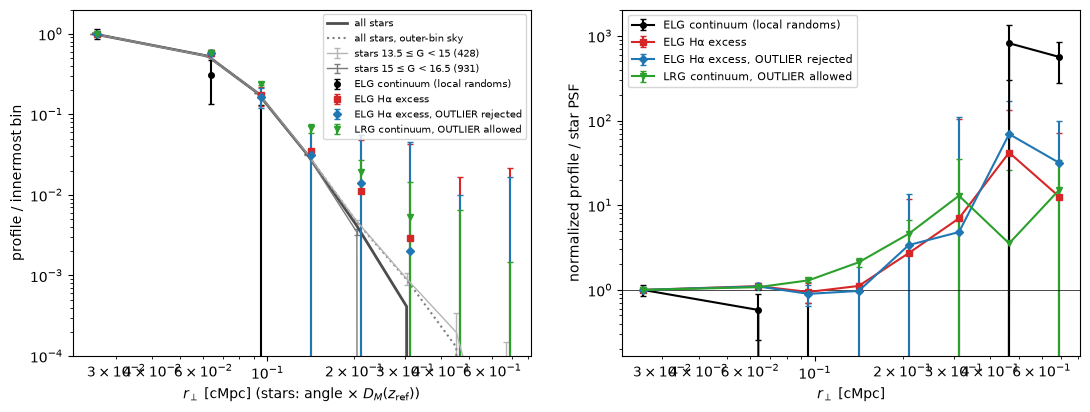

       r [cMpc]      PSF (all stars)  PSF (outer-bin sky)  ELG continuum (local randoms)                  ELG Hα excess ELG Hα excess, OUTLIER rejected LRG continuum, OUTLIER allowed
0.000 - 0.050  1.00e+00 ± 0.0e+00  1.00e+00 ± 0.0e+00           1.00e+00 ± 1.4e-01           1.00e+00 ± 6.0e-02           1.00e+00 ± 6.2e-02           1.00e+00 ± 1.2e-02
0.050 - 0.074  5.29e-01 ± 3.9e-03  5.29e-01 ± 3.9e-03           3.07e-01 ± 1.7e-01           5.86e-01 ± 4.6e-02           5.80e-01 ± 5.5e-02           5.70e-01 ± 1.1e-02
0.074 - 0.110  1.85e-01 ± 9.9e-04  1.85e-01 ± 9.8e-04          -3.01e-02 ± 1.6e-01           1.75e-01 ± 4.7e-02           1.66e-01 ± 4.8e-02           2.39e-01 ± 1.0e-02
0.110 - 0.164  3.19e-02 ± 2.2e-04  3.24e-02 ± 1.6e-04          -2.06e-01 ± 1.5e-01           3.55e-02 ± 3.6e-02           3.10e-02 ± 4.0e-02           6.75e-02 ± 8.0e-03
0.164 - 0.244  4.13e-03 ± 1.7e-04  4.60e-03 ± 8.0e-05          -2.92e-01 ± 1.5e-01           1.12e-02 ± 3.7e-02           1.40e-02 ± 4.2e

In [22]:
# to reload: f = np.load(PSF_OUT_PATH); S_psf, C_psf, psf_g = f['S'], f['C'], f['g']
Sst = S_psf.reshape(-1, n_r, n_wl)
Cst = C_psf.reshape(-1, n_r, n_wl)
has_pix = Cst.sum((1, 2)) > 0

# sky in observed units from the random stack (divide out each random's (1+z)^4)
Sr_obs = S3[is_rand] / ((1 + objs['z'][is_rand]) ** 4)[:, None, None]
sky = Sr_obs.sum(0) / C3[is_rand].sum(0)                      # (n_r, n_wl)

def star_profile(idx):
    # wavelength-averaged profile after subtracting the random-stack sky, (n_r,)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.nanmean(Sst[idx].sum(0) / Cst[idx].sum(0) - sky, axis=-1)

def boot_norm(idx, n_boot=200, seed=1):
    # profile normalized to its innermost bin, with bootstrap-over-stars errors; also the outer-bin-subtracted version
    rng = np.random.default_rng(seed)
    p = star_profile(idx)
    bs_ = np.array([star_profile(rng.choice(idx, len(idx))) for _ in range(n_boot)])
    loc, bs_loc = p - p[-1], bs_ - bs_[:, -1:]
    return (p / p[0], np.std(bs_ / bs_[:, :1], axis=0),
            loc / loc[0], np.std(bs_loc / bs_loc[:, :1], axis=0))

def normed(x, e):
    return x / x[0], np.abs(e / x[0])

star_bins = []
for lo, hi in zip(PSF_G_EDGES[:-1], PSF_G_EDGES[1:]):
    idx = np.flatnonzero(has_pix & (psf_g >= lo) & (psf_g < hi))
    if len(idx) >= 10:
        star_bins.append((f'stars {lo:g} ≤ G < {hi:g} ({len(idx)})', idx, *boot_norm(idx)))
idx_all = np.flatnonzero(has_pix)
psf_all, psf_all_err, psf_loc, psf_loc_err = boot_norm(idx_all)

# galaxy profiles (recomputed, so later cells that reuse `full` / `jk` can't break this)
full_t, jk_t = measure(S3, C3, objs['w'], is_rand, region, N_JACKKNIFE)
t_cont = normed(J_l, err_l)                                                       # continuum, per-region local randoms
t_line = normed(line_excess(full_t[0], j_line, cont), jk_err(line_excess(jk_t[:, 0], j_line, cont)))
curves = [(f'{TRACER} continuum (local randoms)', *t_cont, 'k', 'o'), (f'{TRACER} Hα excess', *t_line, 'C3', 's')]

# reference stacks from other runs, if present: (label, path, 'line' or 'cont', color, marker)
REFERENCE_STACKS = [
    ('ELG Hα excess, OUTLIER rejected', Path('../data/stack_2026-09-24-v2.npz'), 'line', 'C0', 'D'),
    ('LRG continuum, OUTLIER allowed', Path('../data/stack_2026-09-28-lrg-outlier.npz'), 'cont', 'C2', 'v'),
]
for lab, p, kind, col, mk in REFERENCE_STACKS:
    if not p.exists():
        continue
    fe = np.load(p)
    assert np.allclose(fe['r_bins'], r_bins) and np.allclose(fe['wl_bins'], wl_bins)
    reg_e = jackknife_regions(fe['obj_ra'], fe['obj_dec'], fe['is_rand'], N_JACKKNIFE)
    full_e, jk_e = measure(fe['S'].reshape(-1, n_r, n_wl), fe['C'].reshape(-1, n_r, n_wl), fe['obj_w'],
                           fe['is_rand'], reg_e, N_JACKKNIFE)
    if kind == 'line':
        x, e = line_excess(full_e[0], j_line, cont), jk_err(line_excess(jk_e[:, 0], j_line, cont))
    else:   # plain difference of means (no local randoms), mean over continuum bins
        x, e = cont_mean(full_e[0]), jk_err(cont_mean(jk_e[:, 0]))
    curves.append((lab, *normed(x, e), col, mk))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axs[0]
for k, (lab, idx, p, pe, pl, ple) in enumerate(star_bins):
    ax.errorbar(r_c, p, pe, color=plt.cm.Greys(0.4 + 0.2 * k), lw=1, capsize=2, label=lab)
ax.plot(r_c, psf_all, color='0.3', lw=2, label='all stars')
ax.plot(r_c, psf_loc, color='0.5', ls=':', label='all stars, outer-bin sky')
for lab, x, e, c, m in curves:
    ax.errorbar(r_c * 1.03, x, e, color=c, marker=m, ms=4, ls='none', capsize=2, label=lab)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-4, 2)
ax.set_xlabel(r'$r_\perp$ [cMpc] (stars: angle × $D_M(z_{\rm ref})$)')
ax.set_ylabel('profile / innermost bin')
ax.legend(fontsize=7)

ax = axs[1]
for lab, x, e, c, m in curves:
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = x / psf_all
        ratio_err = np.abs(ratio) * np.hypot(e / np.abs(x), psf_all_err / psf_all)
    ax.errorbar(r_c * 1.03, ratio, ratio_err, color=c, marker=m, ms=4, capsize=2, label=lab)
ax.axhline(1, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel('normalized profile / star PSF')
ax.legend(fontsize=8)
plt.show()

print(f"{'r [cMpc]':>15s} {'PSF (all stars)':>20s} {'PSF (outer-bin sky)':>20s} " + " ".join(f"{c[0]:>30s}" for c in curves))
for i in range(n_r):
    print(f"{r_bins[i]:.3f} - {r_bins[i + 1]:.3f} {psf_all[i]:9.2e} ± {psf_all_err[i]:.1e} {psf_loc[i]:9.2e} ± {psf_loc_err[i]:.1e} "
          + " ".join(f"{c[1][i]:18.2e} ± {c[2][i]:.1e}" for c in curves))

# pixel retention: measurements per star vs per unmasked random, same angular bins. A central deficit for
# bright stars means flags are removing pixels on bright sources (as seen at the LRG centres before OUTLIER was allowed).
r_ok = is_rand & (npix_masked == 0) & (C3.sum((1, 2)) > 0)
c_rand = C3[r_ok].sum(-1).mean(0)
print("\nmeasurements per object, stars / unmasked randoms (first four r bins):")
for lab, idx, *_ in star_bins:
    print(f"  {lab:28s}", np.round(Cst[idx].sum(-1).mean(0)[:4] / c_rand[:4], 3))

## flag accounting near the galaxy centres

In the LRG run, OUTLIER (bit 19) was set on 11.8% of rows at LRG centres vs 2.2% at random centres. The pipeline
doesn't set it on catalogued point sources (SOURCE, bit 21), so it was clipping these uncatalogued galaxies. This
notebook allows OUTLIER, and this section checks the accounting for the ELGs. It re-reads a subsample of partitions
**without** any flag cut and follows every row near data ELGs, randoms and the PSF stars:

  rows in the window → rejected by flags (anything not in `ALLOWED_FLAGS`) → removed by the Gaia mask → kept

in radial zones: the two innermost bins (`r < 0.074` cMpc), the third bin, and a reference annulus `0.36 < r < 0.8`.
It also counts how often each bit is set, and how often **OUTLIER** is set per rest-frame wavelength bin. For ELGs
that should peak at Hα, because it's the brightest thing about them.

Bit names are from `talltable/spherextract_fast.py` (`_MP`). Sample: every object touching `FLAG_N_PARTS` random
partitions, plus every partition those objects touch, so no disc is cut off. All PSF stars are included. About 5 min.


In [23]:
FLAG_N_PARTS = 800
FLAG_BITS = {
    0: 'TRANSIENT', 1: 'OVERFLOW', 2: 'SUR_ERROR', 6: 'NONFUNC', 7: 'DICHROIC', 9: 'MISSING_DATA',
    10: 'HOT', 11: 'COLD', 12: 'FULLSAMPLE', 14: 'PHANMISS', 15: 'NONLINEAR', 17: 'PERSIST',
    19: 'OUTLIER', 21: 'SOURCE', 22: 'GHOST', 24: 'GHOST_EXT', 26: 'BLOOM', 27: 'SNOWBALL',
    28: 'HALO', 29: 'SATELLITE_HALO',
}
ZONES = [(0.0, r_bins[2]), (r_bins[2], r_bins[3]), (r_bins[6], R_MAX_CMPC)]   # centre, third bin, reference
ZONE_NAMES = [f'{lo:.3f}-{hi:.3f}' for lo, hi in ZONES]
CLASSES = [TRACER, 'random', 'star']
n_zone, n_cls = len(ZONES), len(CLASSES)

# sample: objects touching FLAG_N_PARTS random partitions (that contain at least one data galaxy), then all their partitions
rng_f = np.random.default_rng(7)
parts_with_data = [p for p, ks in part_objs.items() if (~is_rand[ks]).any()]
seed_parts = rng_f.choice(parts_with_data, size=min(FLAG_N_PARTS, len(parts_with_data)), replace=False)
fl_objs = np.unique(np.concatenate([part_objs[p] for p in seed_parts]))
obj_parts = defaultdict(list)
for p, ks in part_objs.items():
    for k in ks:
        obj_parts[k].append(p)

# one combined position table for the tally: objects (class 0/1) then PSF stars (class 2)
fl_vec   = np.concatenate([obj_vec[fl_objs], psf_vec])
fl_theta = np.concatenate([obj_theta[fl_objs], np.full(n_psf, psf_theta)])
fl_DM    = np.concatenate([obj_D_M[fl_objs], np.full(n_psf, D_M_REF)])
fl_z     = np.concatenate([objs['z'][fl_objs], np.full(n_psf, Z_REF)])
fl_cls   = np.concatenate([is_rand[fl_objs].astype(int), np.full(n_psf, 2)])
fl_self  = np.concatenate([np.full(len(fl_objs), -1), psf_fs_idx])   # star's own index in star_sets[1] (not masked)

fl_part_objs = defaultdict(list)
for j, k in enumerate(fl_objs):
    for p in obj_parts[k]:
        fl_part_objs[p].append(j)
for p, ks in psf_part_objs.items():
    fl_part_objs[p].extend((len(fl_objs) + ks).tolist())
fl_part_objs = {p: np.array(ks) for p, ks in fl_part_objs.items()}

print(f"{(fl_cls == 0).sum()} {TRACER}s, {(fl_cls == 1).sum()} randoms, {(fl_cls == 2).sum()} stars "
      f"in {len(fl_part_objs)} partitions")

3920 ELGs, 17156 randoms, 1359 stars in 3281 partitions


In [24]:
def read_partition_raw(part, ranges):
    # like read_partition but with NO flag cut; returns (hphigh, wavelength, flags) inside `ranges` and the window
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges)
    if len(rgs) == 0:
        return None
    t = pf.read_row_groups(rgs, columns=['hphigh', 'waveid', 'flags'])
    h = t.column('hphigh').to_numpy()
    i = last_range_starting_at_or_before(h, ranges)
    idx = np.flatnonzero((i >= 0) & (h <= ranges[np.maximum(i, 0), 1]))
    waveid = t.column('waveid').to_numpy()[idx]
    pos = np.minimum(np.searchsorted(WAVE_IDS, waveid), len(WAVE_IDS) - 1)
    ok = WAVE_IDS[pos] == waveid
    idx, pos = idx[ok], pos[ok]
    return h[idx], WAVE_WL[pos], t.column('flags').to_numpy()[idx].astype(np.int64)

def gaia_mask_excluding(pix_tree, n_pix, vecs, thetas, self_idx):
    # pixels inside any Gaia mask near these positions, never masking a star's own disc (self_idx >= 0)
    masked = np.zeros(n_pix, dtype=bool)
    targets = set(self_idx[self_idx >= 0].tolist())
    for st, same_set in [(star_sets[0], False), (star_sets[1], True)]:
        cand = np.unique(flatten_idx(st['tree'].query_ball_point(vecs, chord(thetas + st['r_max']))))
        if same_set and targets:
            cand = np.array([c for c in cand if c not in targets], dtype=np.intp)
        if cand.size:
            masked[flatten_idx(pix_tree.query_ball_point(st['vec'][cand], chord(st['r_mask'][cand])))] = True
    return masked

def process_partition_flags(part, ks):
    # per (class, zone): rows, flag-rejected rows, Gaia-masked (unrejected) rows, rows with each bit set;
    # per (class, zone, wl bin): rows, flag-rejected rows, and rows with OUTLIER (bit 19) set.
    out = dict(
        rows=np.zeros((n_cls, n_zone)), rej=np.zeros((n_cls, n_zone)), gaia=np.zeros((n_cls, n_zone)),
        bits=np.zeros((n_cls, n_zone, 32)),
        rows_wl=np.zeros((n_cls, n_zone, n_wl)), rej_wl=np.zeros((n_cls, n_zone, n_wl)),
        outlier_wl=np.zeros((n_cls, n_zone, n_wl)),
    )
    ranges = disc_ranges(fl_vec[ks], fl_theta[ks], partition_span(part))
    if len(ranges) == 0:
        return out
    got = read_partition_raw(part, ranges)
    if got is None or len(got[0]) == 0:
        return out
    hphigh, wl_obs, flags = got
    rejected = (flags & ~ALLOWED_FLAGS) != 0

    upix, inv = np.unique(hphigh, return_inverse=True)
    pix_vec = np.stack(hp.pix2vec(2**HP_HIGH_LEVEL, upix, nest=True), axis=1)
    pix_tree = cKDTree(pix_vec)
    order  = np.argsort(inv, kind='stable')
    counts = np.bincount(inv, minlength=len(upix))
    starts = np.cumsum(counts) - counts

    # objects use the ordinary Gaia mask; stars skip only their own. (For stars, other targets aren't excluded here.)
    masked = gaia_mask_excluding(pix_tree, len(upix), fl_vec[ks], fl_theta[ks], fl_self[ks])
    in_disc = pix_tree.query_ball_point(fl_vec[ks], chord(fl_theta[ks]))
    for j, k in enumerate(ks):
        sel = np.asarray(in_disc[j], dtype=np.intp)
        if sel.size == 0:
            continue
        r_pix = 2 * np.arcsin(0.5 * np.linalg.norm(pix_vec[sel] - fl_vec[k], axis=1)) * fl_DM[k]
        c = fl_cls[k]
        for zi, (lo, hi) in enumerate(ZONES):
            s = sel[(r_pix >= lo) & (r_pix < hi)]
            if s.size == 0:
                continue
            lens = counts[s]
            rows = order[np.repeat(starts[s] - (np.cumsum(lens) - lens), lens) + np.arange(lens.sum())]
            rj = rejected[rows]
            out['rows'][c, zi] += rows.size
            out['rej'][c, zi] += rj.sum()
            out['gaia'][c, zi] += (np.repeat(masked[s], lens) & ~rj).sum()
            out['bits'][c, zi] += ((flags[rows][:, None] >> np.arange(32)) & 1).sum(0)
            i_wl = np.digitize(wl_obs[rows] / (1 + fl_z[k]), wl_bins) - 1
            ok = (i_wl >= 0) & (i_wl < n_wl)
            out['rows_wl'][c, zi] += np.bincount(i_wl[ok], minlength=n_wl)
            out['rej_wl'][c, zi] += np.bincount(i_wl[ok], weights=rj[ok], minlength=n_wl)
            out['outlier_wl'][c, zi] += np.bincount(i_wl[ok], weights=(flags[rows][ok] >> 19) & 1, minlength=n_wl)
    return out

tally = None
t0 = time.time()
with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = [ex.submit(process_partition_flags, p, ks) for p, ks in fl_part_objs.items()]
    for fut in tqdm(as_completed(futures), total=len(futures), desc='partitions (flags)'):
        res = fut.result()
        tally = res if tally is None else {k: tally[k] + res[k] for k in tally}
print(f"done in {time.time() - t0:.0f} s")

partitions (flags):   0%|          | 0/3281 [00:00<?, ?it/s]

done in 656 s


per object, by zone (r in cMpc):
        zone   class   rows/obj  flag-rej %  Gaia-mask %   kept/obj
 0.000-0.074     ELG      47.89       1.41%        3.92%      45.33
 0.000-0.074  random      46.07       1.44%        4.76%      43.21
 0.000-0.074    star      47.00       1.32%        4.82%      44.11
 0.074-0.110     ELG      57.78       1.41%        3.99%      54.66
 0.074-0.110  random      55.72       1.45%        4.85%      52.21
 0.074-0.110    star      56.89       1.44%        4.67%      53.42
 0.362-0.800     ELG    4414.23       1.40%        5.56%    4106.79
 0.362-0.800  random    4248.47       1.44%        5.83%    3939.78
 0.362-0.800    star    4332.97       1.41%        3.09%    4138.25

ELG / random, per object:
   0.000-0.074: rows 1.039   unrejected 1.040   kept 1.049
   0.074-0.110: rows 1.037   unrejected 1.037   kept 1.047
   0.362-0.800: rows 1.039   unrejected 1.039   kept 1.042

fraction of rows with each bit set (%), sorted by ELG - random excess at the centr

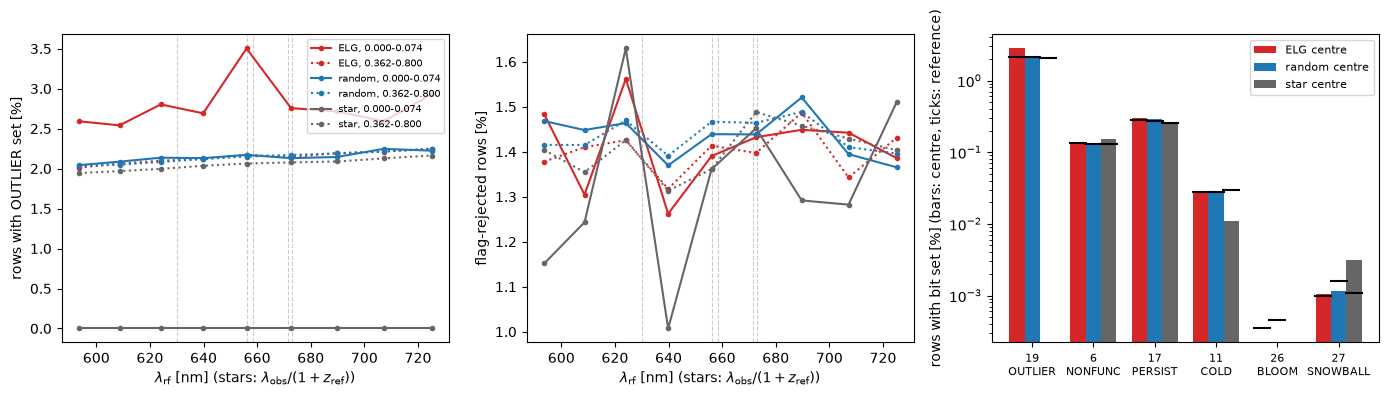

In [25]:
n_per_cls = np.array([(fl_cls == c).sum() for c in range(n_cls)], float)
T = {k: v for k, v in tally.items()}
kept = T['rows'] - T['rej'] - T['gaia']

print("per object, by zone (r in cMpc):")
print(f"{'zone':>12s} {'class':>7s} {'rows/obj':>10s} {'flag-rej %':>11s} {'Gaia-mask %':>12s} {'kept/obj':>10s}")
for zi in range(n_zone):
    for c in range(n_cls):
        nrow = T['rows'][c, zi]
        print(f"{ZONE_NAMES[zi]:>12s} {CLASSES[c]:>7s} {nrow / n_per_cls[c]:10.2f} "
              f"{100 * T['rej'][c, zi] / max(nrow, 1):10.2f}% {100 * T['gaia'][c, zi] / max(nrow, 1):11.2f}% "
              f"{kept[c, zi] / n_per_cls[c]:10.2f}")
print(f"\n{TRACER} / random, per object:")
for zi in range(n_zone):
    lr = lambda x: (x[0, zi] / n_per_cls[0]) / (x[1, zi] / n_per_cls[1])
    print(f"  {ZONE_NAMES[zi]:>12s}: rows {lr(T['rows']):.3f}   unrejected {lr(T['rows'] - T['rej']):.3f}   kept {lr(kept):.3f}")

# which bits: fraction of rows with each bit set, centre vs reference, galaxies vs randoms vs stars
frac = T['bits'] / np.maximum(T['rows'], 1)[..., None]          # (cls, zone, 32)
used = np.flatnonzero(T['bits'].sum((0, 1)) > 0)
order_b = used[np.argsort(-(frac[0, 0, used] - frac[1, 0, used]))]
print(f"\nfraction of rows with each bit set (%), sorted by {TRACER} - random excess at the centre:")
print(f"{'bit':>3s} {'name':>15s} {'reject?':>7s} | " + " ".join(f"{c + ' ' + z:>20s}" for z in ['ctr', 'ref'] for c in CLASSES))
for b in order_b:
    rej_b = 'yes' if (1 << b) & ~ALLOWED_FLAGS else 'no'
    vals = [100 * frac[c, zi, b] for zi in (0, n_zone - 1) for c in range(n_cls)]
    print(f"{b:3d} {FLAG_BITS.get(b, '?'):>15s} {rej_b:>7s} | " + " ".join(f"{v:20.3f}" for v in vals))

# wavelength dependence at the centre (solid) and in the reference annulus (dotted): OUTLIER-set and flag-rejected rows
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
for ax, key, ylab in [(axs[0], 'outlier_wl', 'rows with OUTLIER set [%]'), (axs[1], 'rej_wl', 'flag-rejected rows [%]')]:
    for c, col in zip(range(n_cls), ['C3', 'C0', '0.4']):
        for zi, ls in [(0, '-'), (n_zone - 1, ':')]:
            f_ = T[key][c, zi] / np.maximum(T['rows_wl'][c, zi], 1)
            ax.plot(wl_c * 1e3, 100 * f_, color=col, ls=ls, marker='o', ms=3, label=f'{CLASSES[c]}, {ZONE_NAMES[zi]}')
    for name, x in LINES_NM.items():
        ax.axvline(x, color='0.8', lw=0.8, ls='--', zorder=0)
    ax.set_xlabel(r'$\lambda_{\rm rf}$ [nm] (stars: $\lambda_{\rm obs} / (1 + z_{\rm ref})$)')
    ax.set_ylabel(ylab)
axs[0].legend(fontsize=7)

ax = axs[2]
top = order_b[:6]
x = np.arange(len(top))
for c, col, dx in zip(range(n_cls), ['C3', 'C0', '0.4'], [-0.25, 0, 0.25]):
    ax.bar(x + dx, 100 * frac[c, 0, top], width=0.25, color=col, label=f'{CLASSES[c]} centre')
    ax.scatter(x + dx, 100 * frac[c, n_zone - 1, top], color='k', marker='_', s=150, zorder=3)
ax.set_xticks(x, [f'{b}\n{FLAG_BITS.get(b, "?")}' for b in top], fontsize=8)
ax.set_ylabel('rows with bit set [%] (bars: centre, ticks: reference)')
ax.set_yscale('log')
ax.legend(fontsize=8)
plt.show()